In [15]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import rdMolDraw2D

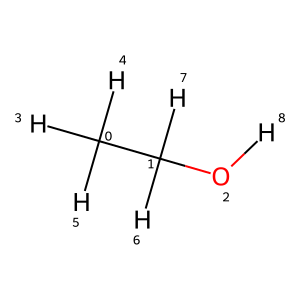

In [16]:
# 1. Create the base molecule (e.g., Ethanol)
mol = Chem.MolFromSmiles("CCO")

# 2. Add explicit hydrogen atoms to the molecule graph
mol_with_hs = Chem.AddHs(mol)

# 3. Configure drawing options to display atom indices
d_options = Draw.rdMolDraw2D.MolDrawOptions()
d_options.addAtomIndices = True

# 4. Generate and display the image with the custom options
Draw.MolToImage(mol_with_hs, options=d_options)

In [17]:
# Define a collection of molecules using SMILES
compounds = {
    "Glycine": "NCC(=O)O",
    "ALA": "NCC(=O)CCC(=O)O",
    "Succinic acid": "O=C(O)CCC(=O)O",
    "Glucose": "OCC1OC(O)C(O)C(O)C1O",
    "Caffeine": "Cn1c(=O)c2c(ncn2C)n(C)c1=O",
    "Aspirin": "CC(=O)Oc1ccccc1C(=O)O"
}

In [18]:
# Convert SMILES into RDKit molecular objects
molecules = {}
for name, smiles in compounds.items():
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        molecules[name] = mol
    else:
        print(f"Invalid SMILES: {name}")

In [6]:
molecules

{'Glycine': <rdkit.Chem.rdchem.Mol at 0x7fb95660a3b0>,
 'ALA': <rdkit.Chem.rdchem.Mol at 0x7fb95660a030>,
 'Succinic acid': <rdkit.Chem.rdchem.Mol at 0x7fb95660a490>,
 'Glucose': <rdkit.Chem.rdchem.Mol at 0x7fb95660a500>,
 'Caffeine': <rdkit.Chem.rdchem.Mol at 0x7fb95660a570>,
 'Aspirin': <rdkit.Chem.rdchem.Mol at 0x7fb95660a5e0>}

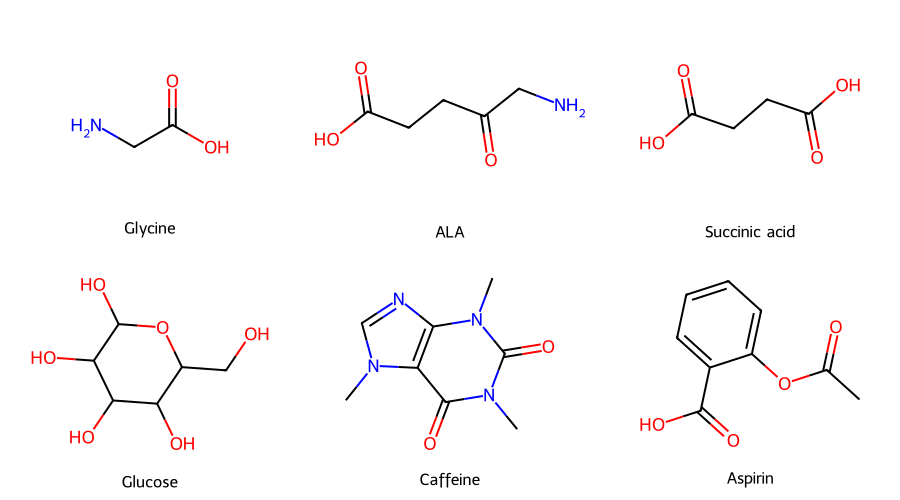

In [19]:
# Visualize the molecules
names = list(molecules.keys())
mols = list(molecules.values())

img = Draw.MolsToGridImage(
    mols,
    molsPerRow=3,
    subImgSize=(300, 250),
    legends=names
)

display(img)

In [20]:
# Define a carboxylic acid SMARTS pattern
carboxylic_acid = Chem.MolFromSmarts("[CX3](=O)[OX2H1]")

for name, mol in molecules.items():
    has_carboxyl = mol.HasSubstructMatch(carboxylic_acid)
    print(name, ":", has_carboxyl)

Glycine : True
ALA : True
Succinic acid : True
Glucose : False
Caffeine : False
Aspirin : True


In [12]:
import pandas as pd

from rdkit.Chem import Descriptors
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem import Lipinski
from rdkit.Chem import Crippen

results = []
for name, mol in molecules.items():
    results.append({
        "Compound": name,
        "Molecular Weight": Descriptors.MolWt(mol),
        "LogP": Crippen.MolLogP(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "H-Bond Donors": Lipinski.NumHDonors(mol),
        "H-Bond Acceptors": Lipinski.NumHAcceptors(mol),
        "Rotatable Bonds": Lipinski.NumRotatableBonds(mol)
    })

df = pd.DataFrame(results)

display(df.round(2))


,Compound,Molecular Weight,LogP,TPSA,H-Bond Donors,H-Bond Acceptors,Rotatable Bonds
0,Glycine,75.07,-0.97,63.32,2,2,1
1,ALA,131.13,-0.62,80.39,2,3,4
2,Succinic acid,118.09,-0.06,74.60,2,2,3
3,Glucose,180.16,-3.22,110.38,5,6,1
4,Caffeine,194.19,-1.03,61.82,0,3,0
5,Aspirin,180.16,1.31,63.60,1,3,2


In [22]:
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs

# Create a Morgan fingerprint generator
generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

# Generate fingerprints
fingerprints = {}
for name, mol in molecules.items():
    fingerprints[name] = generator.GetFingerprint(mol)

# Calculate pairwise similarities
names = list(fingerprints.keys())
similarity_matrix = []
for name1 in names:
    row = []
    for name2 in names:
        similarity = DataStructs.TanimotoSimilarity(
            fingerprints[name1],
            fingerprints[name2]
        )
        row.append(similarity)
    similarity_matrix.append(row)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=names,
    columns=names
)

display(similarity_df.round(2))

,Glycine,ALA,Succinic acid,Glucose,Caffeine,Aspirin
Glycine,1.00,0.53,0.46,0.08,0.03,0.13
ALA,0.53,1.00,0.56,0.06,0.02,0.11
Succinic acid,0.46,0.56,1.00,0.08,0.03,0.14
Glucose,0.08,0.06,0.08,1.00,0.00,0.02
Caffeine,0.03,0.02,0.03,0.00,1.00,0.09
Aspirin,0.13,0.11,0.14,0.02,0.09,1.00


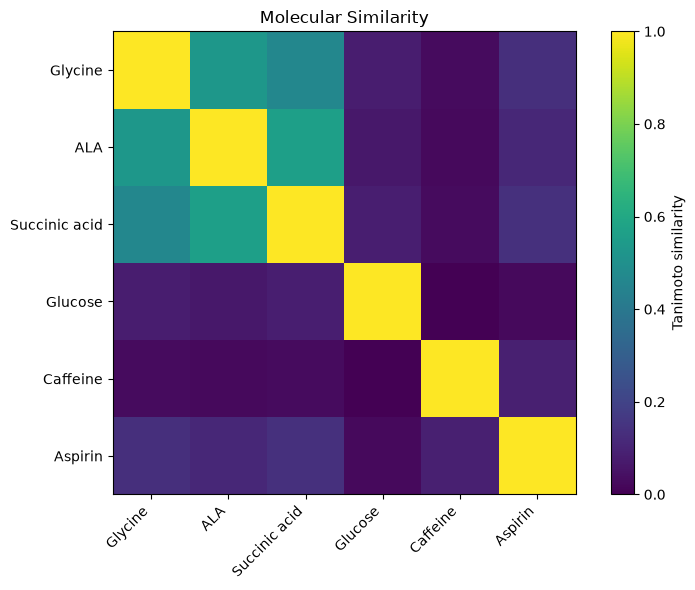

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.imshow(
    similarity_df,
    interpolation="nearest",
    vmin=0,
    vmax=1
)

plt.xticks(
    range(len(names)),
    names,
    rotation=45,
    ha="right"
)

plt.yticks(range(len(names)), names)

plt.colorbar(label="Tanimoto similarity")

plt.title("Molecular Similarity")

plt.tight_layout()
plt.show()

Original molecule: Aspirin
SMILES: CC(=O)Oc1ccccc1C(=O)O


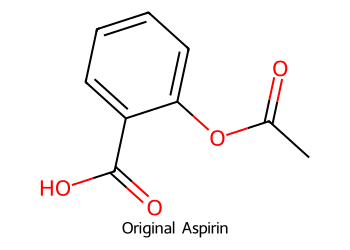

In [29]:
# Use the BRICS (Breaking of Retrosynthetically Interesting Chemical Substructures) tool to fragment a molecule in a realistic way
from rdkit import Chem
from rdkit.Chem import BRICS, Draw

# ============================================================
# 1. Create the original molecule (Aspirin)
# ============================================================

smiles = "CC(=O)Oc1ccccc1C(=O)O"
mol = Chem.MolFromSmiles(smiles)

print("Original molecule: Aspirin")
print("SMILES:", Chem.MolToSmiles(mol))

# Display original aspirin
Draw.MolsToGridImage(
    [mol],
    legends=["Original Aspirin"],
    molsPerRow=1,
    subImgSize=(350, 250)
)


Number of unique fragments: 4
[1*]C(C)=O
[16*]c1ccccc1[16*]
[3*]O[3*]
[6*]C(=O)O


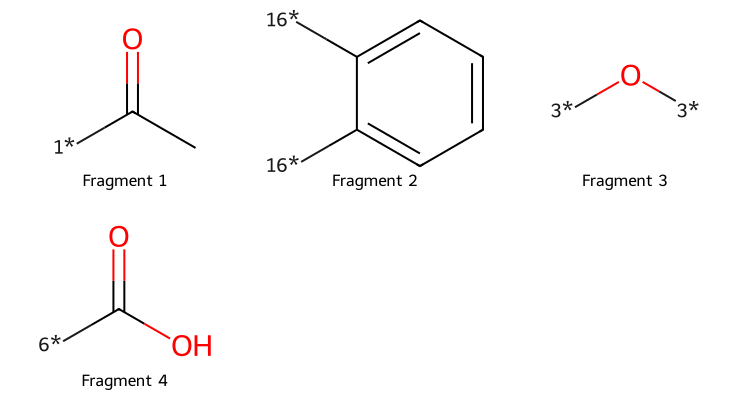

In [30]:
# ============================================================
# 2. Decompose aspirin into BRICS fragments
# ============================================================

fragments = BRICS.BRICSDecompose(mol)

print("\nNumber of unique fragments:", len(fragments))

for frag in sorted(fragments):
    print(frag)

# Convert fragment SMILES into RDKit molecules
fragment_mols = [
    Chem.MolFromSmiles(f) for f in sorted(fragments)
]

# Display fragments
Draw.MolsToGridImage(
    fragment_mols,
    legends=[
        f"Fragment {i+1}"
        for i in range(len(fragment_mols))
    ],
    molsPerRow=3,
    subImgSize=(250, 200)
)

In [31]:
# ============================================================
# 3. Reassemble fragments into candidate molecules
# ============================================================

builder = BRICS.BRICSBuild(
    fragment_mols,
    maxDepth=3
)

# Generate up to 10 candidate molecules
candidates = []
seen = set()

for candidate in builder:

    # Canonical SMILES to avoid duplicates
    smiles = Chem.MolToSmiles(candidate)

    if smiles not in seen:
        seen.add(smiles)
        candidates.append(candidate)

    if len(candidates) >= 10:
        break

print("\nNumber of candidate molecules:", len(candidates))

for i, candidate in enumerate(candidates):
    print(
        f"Candidate {i+1}:",
        Chem.MolToSmiles(candidate)
    )


Number of candidate molecules: 8
Candidate 1: O=C(O)c1ccccc1C(=O)O
Candidate 2: O=C(O)c1ccccc1-c1ccccc1C(=O)O
Candidate 3: O=C(O)c1ccccc1-c1ccccc1-c1ccccc1C(=O)O
Candidate 4: CC(=O)Oc1ccccc1-c1ccccc1C(=O)O
Candidate 5: CC(=O)Oc1ccccc1C(=O)O
Candidate 6: O=C(O)c1ccccc1Oc1ccccc1C(=O)O
Candidate 7: CC(=O)Oc1ccccc1OC(C)=O
Candidate 8: CC(=O)OC(C)=O


# ============================================================
# 4. Compare original aspirin with generated candidates
# ============================================================

comparison_mols = [mol] + candidates

legends = ["Original Aspirin"] + [
    f"Candidate {i+1}"
    for i in range(len(candidates))
]

Draw.MolsToGridImage(
    comparison_mols,
    legends=legends,
    molsPerRow=3,
    subImgSize=(300, 250)
)